In [45]:
# Import Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [46]:
# Load Dataset
df = pd.read_excel("spotify_dataset.xlsx")

In [47]:
# Clean Dataset
df.head()
df.info()
df.describe()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   user_id                 5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   country                 5000 non-null   object 
 3   subscription_plan       5000 non-null   object 
 4   monthly_fee             5000 non-null   float64
 5   listening_hours         5000 non-null   float64
 6   skip_rate               5000 non-null   float64
 7   playlists_created       5000 non-null   int64  
 8   active_days             5000 non-null   int64  
 9   inactivity_days         5000 non-null   int64  
 10  favorite_genre          5000 non-null   object 
 11  podcast_hours           5000 non-null   float64
 12  artist_diversity_score  5000 non-null   float64
 13  engagement_score        5000 non-null   float64
 14  churn_probability       5000 non-null   

(5000, 20)

In [48]:
# Missing Values
df.isnull().sum()

user_id                   0
age                       0
country                   0
subscription_plan         0
monthly_fee               0
listening_hours           0
skip_rate                 0
playlists_created         0
active_days               0
inactivity_days           0
favorite_genre            0
podcast_hours             0
artist_diversity_score    0
engagement_score          0
churn_probability         0
churn_flag                0
renewal_status            0
campaign_response         0
revenue_priority_score    0
retention_risk_score      0
dtype: int64

In [49]:
# Duplicate Rows
df.duplicated().sum()

0

In [50]:
# Data Types
df.dtypes

user_id                    object
age                         int64
country                    object
subscription_plan          object
monthly_fee               float64
listening_hours           float64
skip_rate                 float64
playlists_created           int64
active_days                 int64
inactivity_days             int64
favorite_genre             object
podcast_hours             float64
artist_diversity_score    float64
engagement_score          float64
churn_probability         float64
churn_flag                  int64
renewal_status             object
campaign_response          object
revenue_priority_score    float64
retention_risk_score        int64
dtype: object

In [51]:
# Standardize Text Columns
text_columns = [
    'country',
    'subscription_plan',
    'favorite_genre',
    'renewal_status',
    'campaign_response']

for col in text_columns:
    df[col] = df[col].str.strip().str.title()

In [52]:
# Remove Invalid Numeric Values
df = df[(df['age'] >= 13) & (df['age'] <= 100)]
# Monthly Fee
df = df[df['monthly_fee'] >= 0]
# Listening Hours
df = df[df['listening_hours'] >= 0]
# Podcast Hours
df = df[df['podcast_hours'] >= 0]
# Active and Inactivity Days
df = df[df['active_days'] >= 0]
df = df[df['inactivity_days'] >= 0]
# Skip Rate
df = df[(df['skip_rate'] >= 0) & (df['skip_rate'] <= 1)]
# Churn Probability
df = df[(df['churn_probability'] >= 0) &
        (df['churn_probability'] <= 1)]
# Engagement Score
df = df[(df['engagement_score'] >= 0) &
        (df['engagement_score'] <= 100)]

In [53]:
# Verifying clean data
print(df.info())

print(df.describe())

print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 4969 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   user_id                 4969 non-null   object 
 1   age                     4969 non-null   int64  
 2   country                 4969 non-null   object 
 3   subscription_plan       4969 non-null   object 
 4   monthly_fee             4969 non-null   float64
 5   listening_hours         4969 non-null   float64
 6   skip_rate               4969 non-null   float64
 7   playlists_created       4969 non-null   int64  
 8   active_days             4969 non-null   int64  
 9   inactivity_days         4969 non-null   int64  
 10  favorite_genre          4969 non-null   object 
 11  podcast_hours           4969 non-null   float64
 12  artist_diversity_score  4969 non-null   float64
 13  engagement_score        4969 non-null   float64
 14  churn_probability       4969 non-null   float

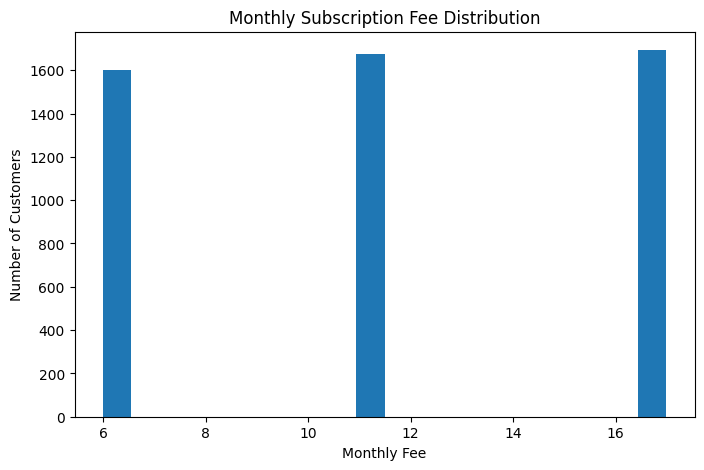

In [54]:
# Revenue Distribution
plt.figure(figsize=(8,5))
plt.hist(df["monthly_fee"], bins=20)
plt.title("Monthly Subscription Fee Distribution")
plt.xlabel("Monthly Fee")
plt.ylabel("Number of Customers")
plt.show()

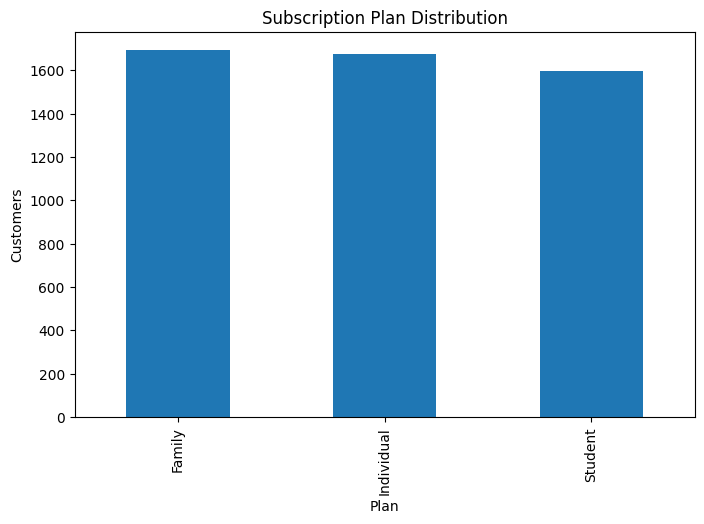

In [55]:
# Subscription Plan
plt.figure(figsize=(8,5))

df["subscription_plan"].value_counts().plot(kind="bar")

plt.title("Subscription Plan Distribution")
plt.xlabel("Plan")
plt.ylabel("Customers")
plt.show()

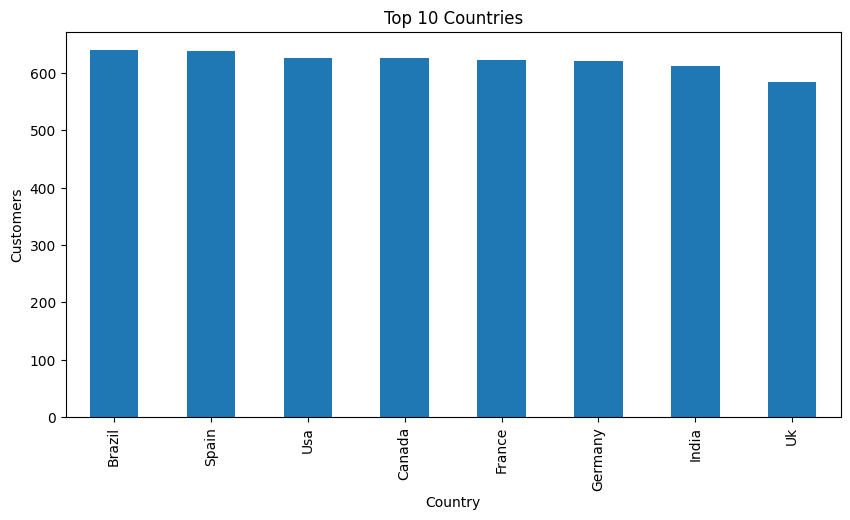

In [56]:
# Top Countries
top_country = df["country"].value_counts().head(10)
plt.figure(figsize=(10,5))
top_country.plot(kind="bar")
plt.title("Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Customers")
plt.show()

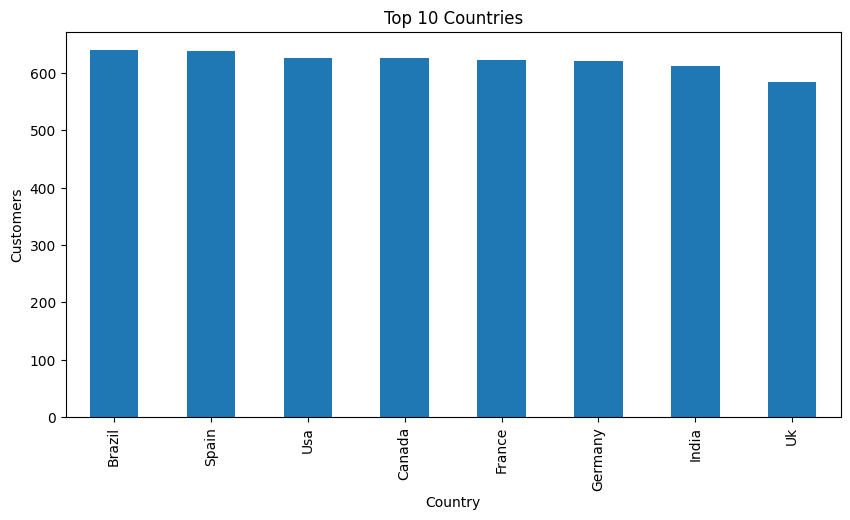

In [57]:
# Churn Distribution
top_country = df["country"].value_counts().head(10)

plt.figure(figsize=(10,5))
top_country.plot(kind="bar")

plt.title("Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Customers")
plt.show()

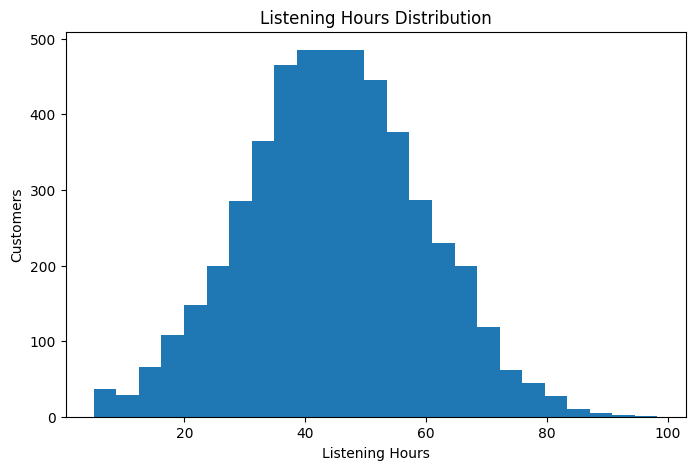

In [58]:
# Listening Hours
plt.figure(figsize=(8,5))

plt.hist(df["listening_hours"], bins=25)

plt.xlabel("Listening Hours")
plt.ylabel("Customers")
plt.title("Listening Hours Distribution")
plt.show()

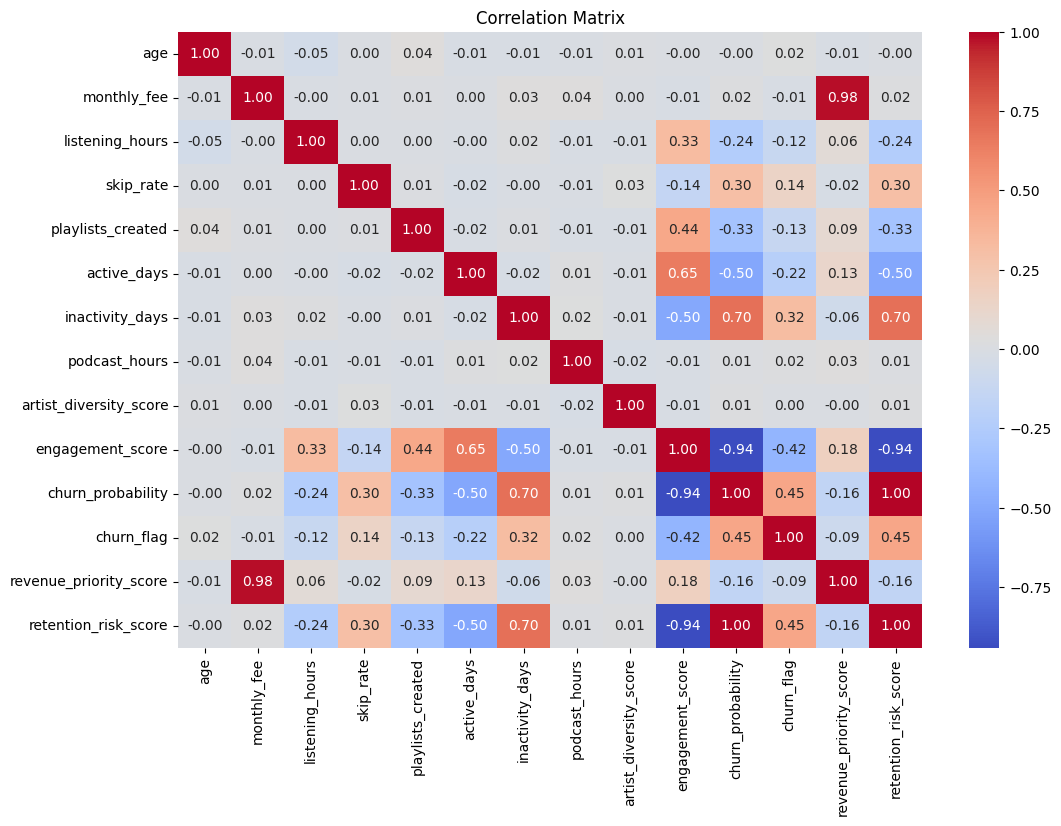

In [59]:
# Correlation Matrix
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f")

plt.title("Correlation Matrix")
plt.show()

In [60]:
# Feature Engineering
## Engagement Score
df["engagement_score_new"] = (
      df["listening_hours"]*0.5
    + df["playlists_created"]*0.3
    + df["podcast_hours"]*0.2)

## Revenue Segment
df["revenue_segment"] = np.select(
    [
        df["monthly_fee"] <= 5.99,
        (df["monthly_fee"] > 5.99) & (df["monthly_fee"] <= 10.99),
        df["monthly_fee"] > 10.99],
    [
        "Bronze",
        "Silver",
        "Gold"])

## High Value Customer
median_fee = df["monthly_fee"].median()

df["high_value_customer"] = np.where(
    df["monthly_fee"] >= median_fee,
    1,
    0)

## Profitability Score
df["profitability_score"] = (
      df["monthly_fee"]*0.6
    + df["engagement_score"]*0.4)

## Retention Risk Score
df["retention_risk"] = (
      df["inactivity_days"]*0.5
    + df["skip_rate"]*100*0.3
    - df["listening_hours"]*0.2)

print(df["monthly_fee"].unique())
print(df["monthly_fee"].value_counts())

[10.99  5.99 16.99]
monthly_fee
16.99    1693
10.99    1677
5.99     1599
Name: count, dtype: int64


                 count   mean       sum
revenue_segment                        
Bronze            1599   5.99   9578.01
Gold              1693  16.99  28764.07
Silver            1677  10.99  18430.23


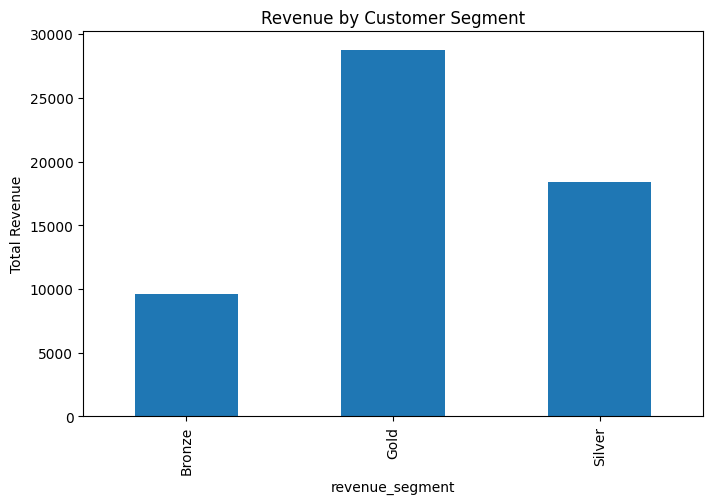

                listening_hours  podcast_hours  playlists_created  \
renewal_status                                                      
Cancelled             42.625587       7.620891           3.751318   
Continued             46.237381       7.472727           4.268913   
Renewed               46.295722       7.467609           4.251337   

                engagement_score_new  
renewal_status                        
Cancelled                  23.962367  
Continued                  25.893910  
Renewed                    25.916784  


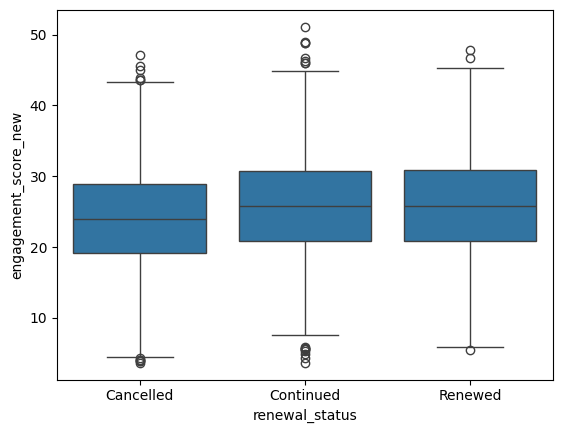

            listening_hours  skip_rate  inactivity_days  engagement_score_new
churn_flag                                                                   
0                 46.263879   0.234209        10.098196             25.904299
1                 42.625587   0.268040        14.773838             23.962367


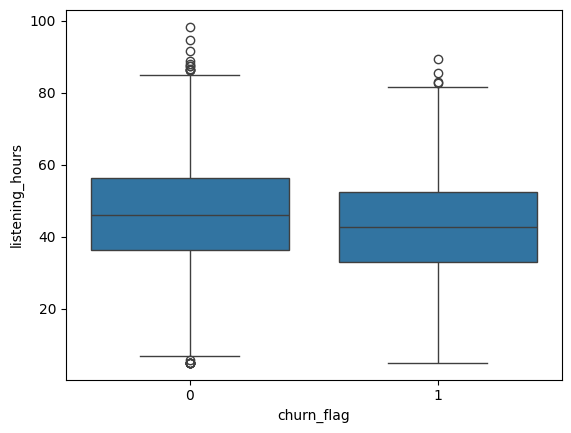

country
Brazil     7374.60
Usa        7322.74
Canada     7278.74
Spain      7204.62
Germany    7110.79
France     6986.78
India      6928.88
Uk         6565.16
Name: monthly_fee, dtype: float64
subscription_plan
Family        28764.07
Individual    18430.23
Student        9578.01
Name: monthly_fee, dtype: float64


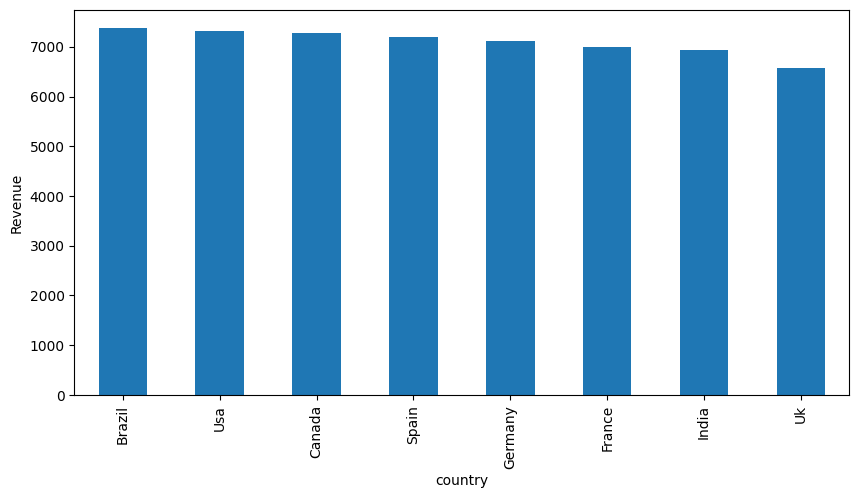

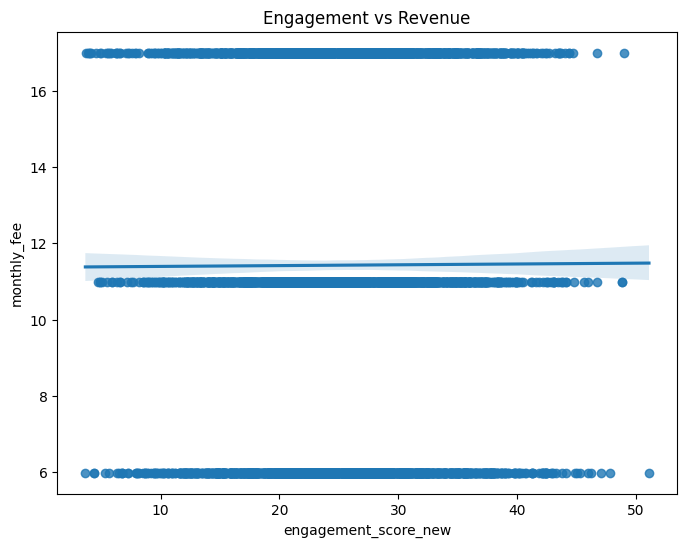

0.003524961025676708
                   monthly_fee  renewal_status  churn_flag
campaign_response                                         
Clicked              11.422845       28.328446    0.404106
Ignored              11.409885       25.432756    0.422548
Subscribed           11.463788       25.024728    0.441147


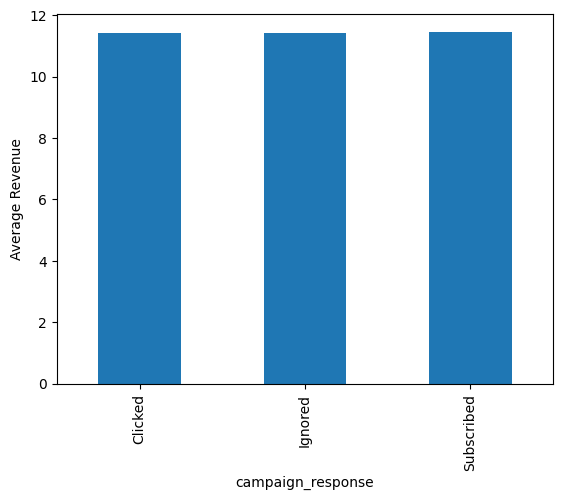

In [61]:
# Financial Analysis
## Which customer segments generate the highest subscription revenue?
segment_revenue = df.groupby("revenue_segment")["monthly_fee"].agg(
    ["count","mean","sum"])

print(segment_revenue)

segment_revenue["sum"].plot(
    kind="bar",
    figsize=(8,5))

plt.title("Revenue by Customer Segment")
plt.ylabel("Total Revenue")
plt.show()

## What customer behaviours influence subscription renewal?
renewal = df.groupby("renewal_status")[[
    "listening_hours",
    "podcast_hours",
    "playlists_created",
    "engagement_score_new"
]].mean()

print(renewal)

sns.boxplot(
    x="renewal_status",
    y="engagement_score_new",
    data=df)

plt.show()

## What factors increase churn?
churn = df.groupby("churn_flag")[[
    "listening_hours",
    "skip_rate",
    "inactivity_days",
    "engagement_score_new"
]].mean()

print(churn)

sns.boxplot(
    x="churn_flag",
    y="listening_hours",
    data=df)

plt.show()

## Which countries and subscription plans are most profitable?
### Country
country_rev = df.groupby("country")["monthly_fee"].sum().sort_values(ascending=False)

print(country_rev.head(10))
### Plan
plan_rev = df.groupby("subscription_plan")["monthly_fee"].sum()

print(plan_rev)

country_rev.head(10).plot(
    kind="bar",
    figsize=(10,5))

plt.ylabel("Revenue")
plt.show()

## Does engagement increase financial value?
plt.figure(figsize=(8,6))

sns.regplot(
    x="engagement_score_new",
    y="monthly_fee",
    data=df)

plt.title("Engagement vs Revenue")
plt.show()

### Correlation
corr = df["engagement_score_new"].corr(df["monthly_fee"])

print(corr)

## Which marketing campaigns retain profitable customers?
campaign = df.groupby("campaign_response").agg({

    "monthly_fee":"mean",
    "renewal_status":lambda x:(x=="Renewed").mean()*100,
    "churn_flag":"mean"})

print(campaign)

campaign["monthly_fee"].plot(kind="bar")

plt.ylabel("Average Revenue")

plt.show()

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       604
           1       1.00      1.00      1.00       390

    accuracy                           1.00       994
   macro avg       1.00      1.00      1.00       994
weighted avg       1.00      1.00      1.00       994



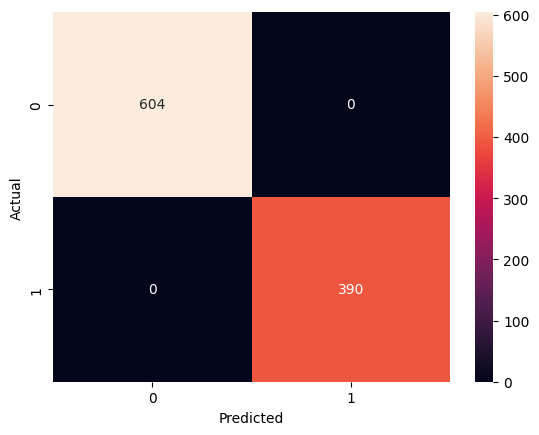

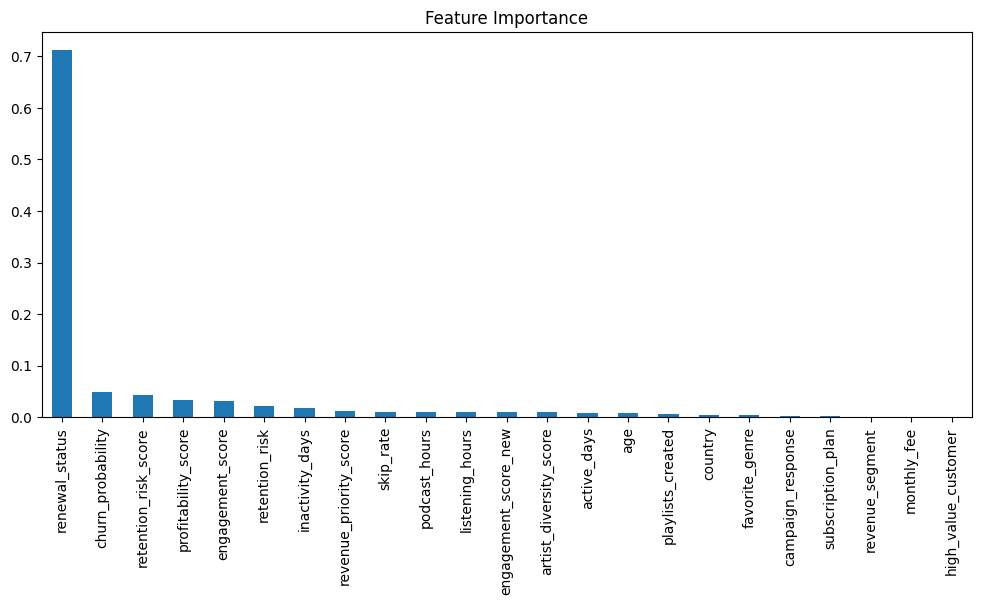

In [62]:
# Predict Customer Churn
df_ml = df.copy()

encoder = LabelEncoder()

categorical_cols = df_ml.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    df_ml[col] = encoder.fit_transform(df_ml[col].astype(str))
    
## Features
X = df_ml.drop(columns=["churn_flag", "user_id"], errors='ignore')
y = df_ml["churn_flag"]

### Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
print(classification_report(y_test, pred))

# Confusion Matrix
cm = confusion_matrix(y_test,pred)

sns.heatmap(cm,annot=True,fmt="d")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

# Feature Importance
importance = pd.Series(
    rf.feature_importances_,
    index=X.columns).sort_values(ascending=False)

importance.plot(
    kind="bar",
    figsize=(12,5))

plt.title("Feature Importance")

plt.show()

In [63]:
# Customer Lifetime Value (CLV)
df["months_active"] = (df["active_days"] / 30).round().clip(lower=1)
df["estimated_clv"] = df["monthly_fee"] * df["months_active"]

In [64]:
# Export Final Dataset
dashboard_df = df.copy()

dashboard_df.to_csv(
    "dashboard_dataset.csv",
    index=False)

print("Dashboard dataset exported successfully!")

Dashboard dataset exported successfully!
